# EDA visual: dónde y cuándo se retrasan los pedidos de Olist

**Autor:** Alexis · **Base:** misma tabla que `01_exploracion_y_target.ipynb` (Mathias)

Este notebook **no limpia ni redefine nada**. Toma el target oficial (`build_target`) y las variables oficiales (`build_features`) de `src/` y las muestra en gráficos. Cada gráfico responde una pregunta de operaciones logísticas.

**Regla de lectura de todos los gráficos:**
- La línea punteada gris es la **tasa global de retraso (6,79 %)**. Lo que importa es cuánto se aleja cada grupo de esa línea.
- Se muestra la cantidad de pedidos (*n*) de cada grupo. Una tasa alta con pocos pedidos es ruido, no un hallazgo.
- Una asociación no es una causa. Lo que se ve acá son hipótesis para el modelo y para el negocio.

**Para la demo de 4 minutos:** los gráficos 1 a 4. El anexo queda para preguntas del jurado.

## 0. Preparación

In [1]:
from pathlib import Path
import sys

# Igual que el notebook 01: funciona abierto desde notebooks/ o desde la raíz.
CURRENT_DIR = Path.cwd()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from src.data_loading import load_raw_tables
from src.features import build_features
from src.target import TARGET_COL, build_target

# Guardar cada gráfico como PNG en reports/figuras/ (para las diapositivas).
# Los PNG NO están en el .gitignore: acordar con el equipo antes de subirlos.
GUARDAR_FIGURAS = True
FIG_DIR = PROJECT_ROOT / "reports" / "figuras"
if GUARDAR_FIGURAS:
    FIG_DIR.mkdir(parents=True, exist_ok=True)

### Estilo común

Un solo estilo para todos los gráficos, así se leen como un conjunto:
- **Naranja** = el grupo de mayor riesgo, el que hay que mirar. **Azul** = SP, cuando se lo separa del resto.
- Gris para contexto (volumen, tasa global).
- Sin doble eje Y: cuando hay dos medidas de distinta escala (volumen y tasa), van en dos paneles.

In [2]:
AZUL, NARANJA = "#2a78d6", "#eb6834"      # SP / resto de Brasil
GRIS, GRIS_CLARO = "#8a8984", "#d9d8d4"   # contexto
TINTA, TINTA_2 = "#0b0b0b", "#52514e"     # textos

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRIS_CLARO, "axes.labelcolor": TINTA_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#ecebe8", "grid.linewidth": 0.8,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10, "legend.frameon": False, "axes.axisbelow": True,
})
pct = mtick.PercentFormatter(1.0, decimals=0)
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]


def tasa_por(df, columna):
    """Cantidad de pedidos y tasa de retraso por grupo. La media de una columna 0/1 es una proporción."""
    return df.groupby(columna, observed=True)[TARGET_COL].agg(n="size", tasa="mean")


def linea_global(ax, tasa, horizontal=True):
    """Dibuja la tasa global como referencia."""
    if horizontal:
        ax.axhline(tasa, color=GRIS, ls="--", lw=1, zorder=1)
    else:
        ax.axvline(tasa, color=GRIS, ls="--", lw=1, zorder=1)


def guardar(fig, nombre):
    if GUARDAR_FIGURAS:
        fig.savefig(FIG_DIR / f"{nombre}.png", dpi=150, bbox_inches="tight")

### Datos: exactamente los mismos que usa el modelo

`build_target` deja los pedidos entregados del período oficial (ene 2017 a ago 2018). `build_features` arma una fila por pedido con lo que se conoce al aprobar el pago. Si los números de abajo no dan 96.203 y 96.189, algo cambió en `src/` o en los CSV.

In [3]:
tables = load_raw_tables()
pedidos = build_target(tables["orders"])
df = build_features(**{**tables, "orders": pedidos}, anchor="aprobacion")

# Columnas auxiliares SOLO para graficar (no son variables del modelo).
df["anio_mes"] = df["order_purchase_timestamp"].dt.to_period("M")
df["region"] = np.where(df["customer_state"].eq("SP"), "SP", "Resto de Brasil")

TASA_GLOBAL = df[TARGET_COL].mean()
print(f"Pedidos con target: {len(pedidos):,}")
print(f"Pedidos para el modelo (con aprobación): {len(df):,}")
print(f"Tasa global de retraso: {TASA_GLOBAL:.2%}")
assert len(df) == 96_189, "La base no coincide con la del notebook 01"

Pedidos con target: 96,203
Pedidos para el modelo (con aprobación): 96,189
Tasa global de retraso: 6.79%


### Contexto en tres números

El tercero usa la fecha real de entrega. Sirve para dimensionar el problema, pero **nunca entra al modelo** (sería fuga de información: decisión 4).

In [4]:
dias_tarde = (
    pedidos["order_delivered_customer_date"].dt.normalize()
    - pedidos["order_estimated_delivery_date"].dt.normalize()
).dt.days
dias_tarde = dias_tarde[pedidos[TARGET_COL] == 1]

print(f"Pedidos retrasados: {int(df[TARGET_COL].sum()):,} de {len(df):,} ({TASA_GLOBAL:.2%})")
print(f"Cuando llega tarde, llega con una demora mediana de {dias_tarde.median():.0f} días "
      f"(el 10 % de los retrasados supera los {dias_tarde.quantile(0.9):.0f} días).")

Pedidos retrasados: 6,531 de 96,189 (6.79%)
Cuando llega tarde, llega con una demora mediana de 7 días (el 10 % de los retrasados supera los 22 días).


## 1. ¿Cuándo se estresa la red? Tasa de retraso mes a mes

**Pregunta de negocio:** ¿el retraso es constante o hay períodos críticos?

Se usa **año-mes** y no `purchase_month` solo: el período tiene enero a agosto dos veces (2017 y 2018) y septiembre a diciembre una vez. Contar por mes sin año mezcla años y hace parecer que septiembre "vende menos".

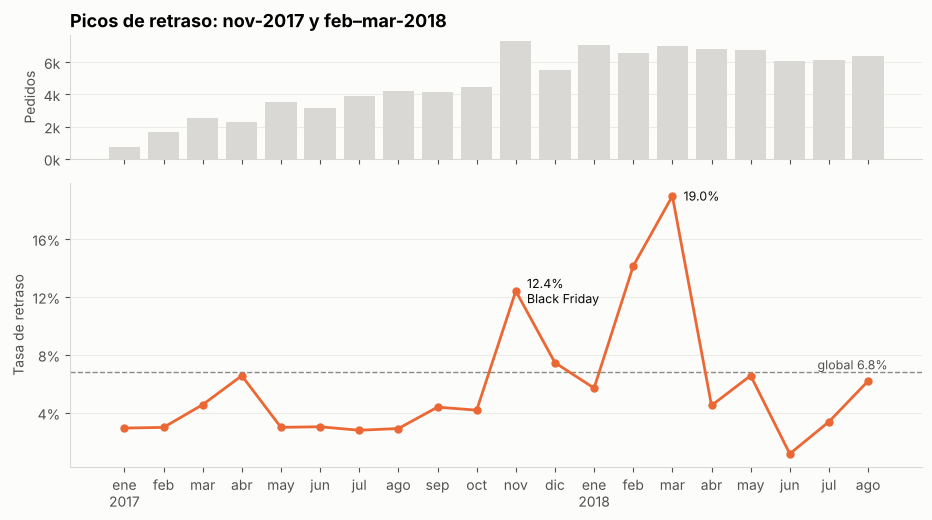

anio_mes,2017-01,2017-02,2017-03,2017-04,2017-05,2017-06,2017-07,2017-08,2017-09,2017-10,2017-11,2017-12,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08
n,748.000,1641.00,2546.000,2303.000,3545.00,3135.00,3872.000,4193.000,4150.000,4478.000,7288.000,5513.000,7069.000,6555.000,7003.00,6798.000,6749.000,6096.000,6156.000,6351.000
tasa,0.029,0.03,0.046,0.066,0.03,0.03,0.028,0.029,0.044,0.042,0.124,0.075,0.057,0.141,0.19,0.045,0.066,0.012,0.034,0.062
plazo_mediano,39.000,31.00,23.000,26.000,24.00,24.00,24.000,23.000,23.000,23.000,23.000,28.000,26.000,25.000,22.00,24.000,22.000,28.000,20.000,14.000


In [5]:
mensual = tasa_por(df, "anio_mes")
x = np.arange(len(mensual))
etiquetas = [f"{MESES[p.month - 1]}\n{p.year}" if p.month == 1 else MESES[p.month - 1]
             for p in mensual.index]

fig, (ax_vol, ax_tasa) = plt.subplots(
    2, 1, figsize=(11, 5.6), sharex=True, gridspec_kw={"height_ratios": [1, 2.3], "hspace": 0.12}
)

# Panel superior: volumen (contexto)
ax_vol.bar(x, mensual["n"], color=GRIS_CLARO, width=0.8)
ax_vol.set_ylabel("Pedidos")
ax_vol.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
ax_vol.set_title("Picos de retraso: nov-2017 y feb–mar-2018")

# Panel inferior: tasa de retraso
ax_tasa.plot(x, mensual["tasa"], color=NARANJA, lw=2, marker="o", ms=5, zorder=3)
linea_global(ax_tasa, TASA_GLOBAL)
ax_tasa.text(len(x) - 0.5, TASA_GLOBAL, f"global {TASA_GLOBAL:.1%}", color=TINTA_2,
             va="bottom", ha="right", fontsize=9)
ax_tasa.yaxis.set_major_locator(mtick.MultipleLocator(0.04))
ax_tasa.yaxis.set_major_formatter(pct)
ax_tasa.set_ylabel("Tasa de retraso")
ax_tasa.set_xticks(x, etiquetas)

for periodo, texto in [("2017-11", "Black Friday"), ("2018-03", "")]:
    i = list(mensual.index.astype(str)).index(periodo)
    ax_tasa.annotate(f"{mensual['tasa'].iloc[i]:.1%}" + (f"\n{texto}" if texto else ""),
                     (x[i], mensual["tasa"].iloc[i]), xytext=(8, 0), textcoords="offset points",
                     va="center", color=TINTA, fontsize=9)
guardar(fig, "01_tasa_mensual")
plt.show()

# ¿Cambió el plazo que promete Olist? Mediana de días prometidos por mes, junto a la tasa.
plazo_mes = df.groupby("anio_mes")["promised_days"].median().rename("plazo_mediano")
display(mensual.join(plazo_mes).assign(tasa=lambda d: d["tasa"].round(3)).T)

**Lectura:**
- En noviembre de 2017 el volumen sube un 63 % respecto de octubre (Black Friday) y la tasa sube a **12,4 %**. Más carga, más retrasos: el comportamiento esperable de una red sin capacidad de reserva.
- Febrero y marzo de 2018 son **peores (14,1 % y 19,0 %) con un volumen similar al de enero**. Ahí el volumen no lo explica. Algo pasó en la operación (transporte, clima, feriados) que estos datos no muestran.
- Junio de 2018 baja a 1,2 %. No conviene concluir "mejoró la logística": ese mes el **plazo mediano prometido saltó a 28 días** (venía de 22 en mayo). Y marzo, el peor mes, tuvo el plazo más corto del semestre (22 días). Prometer más días compra cumplimiento. Es una asociación, no una prueba: puede haber otros cambios ese mes.

**Para el modelo:** la tasa no es estable en el tiempo. Por eso la validación es temporal (decisión 5) y no aleatoria: un split aleatorio mezclaría marzo 2018 en train y test.

## 2. ¿Dónde falla el último tramo? Tasa de retraso por estado del cliente

**Pregunta de negocio:** ¿el retraso depende de adónde va el pedido?

Se muestran solo los estados con **al menos 300 pedidos**. Los otros seis (RR, AP, AC, AM, RO, TO) tienen entre 40 y 274 pedidos; su tasa es demasiado inestable para compararla.

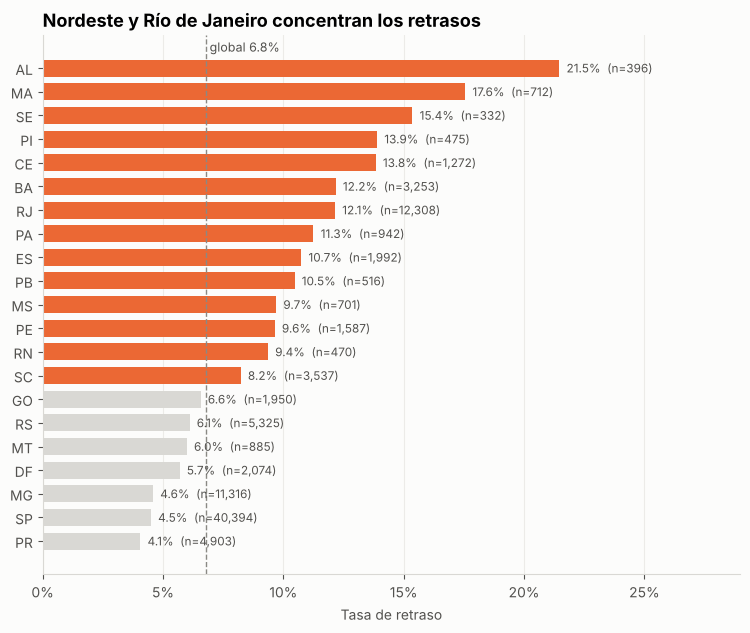

Excluidos por tener menos de 300 pedidos: AC, AM, AP, RO, RR, TO


,% de los pedidos,% de los retrasos
customer_state,,
SP,42.0,27.8
RJ,12.8,22.9
MG,11.8,7.9
BA,3.4,6.1
RS,5.5,5.0


In [6]:
N_MIN = 300
por_estado = tasa_por(df, "customer_state")
excluidos = por_estado[por_estado["n"] < N_MIN]
por_estado = por_estado[por_estado["n"] >= N_MIN].sort_values("tasa")

colores = [NARANJA if t > TASA_GLOBAL else GRIS_CLARO for t in por_estado["tasa"]]
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(por_estado.index, por_estado["tasa"], color=colores, height=0.72)
linea_global(ax, TASA_GLOBAL, horizontal=False)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.xaxis.set_major_formatter(pct)
ax.set_xlabel("Tasa de retraso")
ax.set_title("Nordeste y Río de Janeiro concentran los retrasos")

for estado, fila in por_estado.iterrows():
    ax.text(fila["tasa"] + 0.003, estado, f"{fila['tasa']:.1%}  (n={int(fila['n']):,})",
            va="center", fontsize=8.5, color=TINTA_2)
ax.text(TASA_GLOBAL, len(por_estado) - 0.3, f" global {TASA_GLOBAL:.1%}", color=TINTA_2, fontsize=9)
ax.set_xlim(0, por_estado["tasa"].max() * 1.35)
guardar(fig, "02_tasa_por_estado")
plt.show()

# Peso de cada estado en el total de retrasos (lo que importa para priorizar)
retrasados = df[df[TARGET_COL] == 1]
peso = pd.DataFrame({
    "% de los pedidos": df["customer_state"].value_counts(normalize=True),
    "% de los retrasos": retrasados["customer_state"].value_counts(normalize=True),
}).sort_values("% de los retrasos", ascending=False).head(5).mul(100).round(1)
print(f"Excluidos por tener menos de {N_MIN} pedidos: {', '.join(excluidos.index)}")
display(peso)

**Lectura:**
- Los estados del **Nordeste** (AL 21,5 %, MA 17,6 %, SE 15,4 %) triplican la tasa global. Son destinos lejos de los centros de despacho del Sudeste.
- **Río de Janeiro es el dato más accionable.** No tiene la tasa más alta (12,1 %), pero es el segundo mercado: tiene el **12,8 % de los pedidos y el 22,9 % de los retrasos**. Mejorar RJ mueve el total más que mejorar Alagoas.
- SP, PR y MG están por debajo del promedio: cerca de donde están la mayoría de los vendedores.

**Cuidado:** este gráfico mezcla dos cosas, la distancia y la calidad de la red en destino. El gráfico 3 intenta separarlas.

## 3. ¿Importa que el vendedor esté en otro estado? Sí, pero no donde parece

**Pregunta de negocio:** ¿los envíos entre estados son más riesgosos?

Mirado en bruto, sí: **8,1 %** con vendedor de otro estado contra **4,5 %** con vendedor del mismo estado. Pero SP tiene la mayoría de los vendedores *y* de los clientes, y una tasa baja. Si no se separa SP, la comparación mezcla geografía con distancia.

,n,tasa
seller_other_state,,
False,34485,0.045
True,61704,0.081


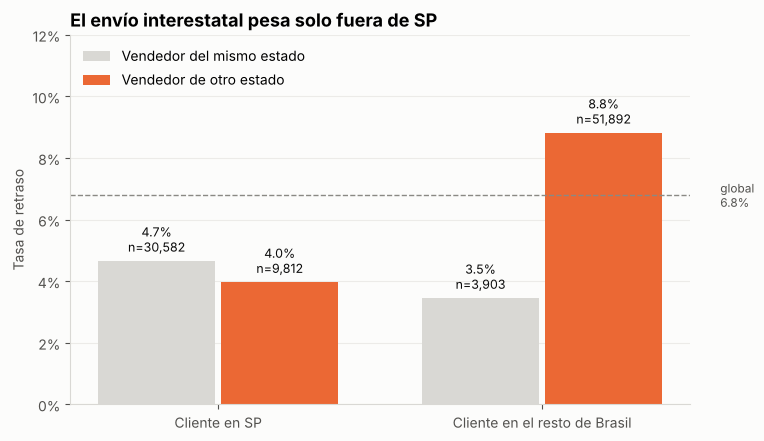

n   tasa
region          seller_other_state              
Resto de Brasil False                3903  0.035
                True                51892  0.088
SP              False               30582  0.047
                True                 9812  0.040

In [7]:
cruce = df.groupby(["region", "seller_other_state"])[TARGET_COL].agg(n="size", tasa="mean")
display(tasa_por(df, "seller_other_state").assign(tasa=lambda d: d["tasa"].round(3)))

regiones = ["SP", "Resto de Brasil"]
grupos = [("False", "Vendedor del mismo estado", GRIS_CLARO), ("True", "Vendedor de otro estado", NARANJA)]
x = np.arange(len(regiones))
ancho = 0.36

fig, ax = plt.subplots(figsize=(8, 4.8))
for k, (valor, etiqueta, color) in enumerate(grupos):
    tasas = [cruce.loc[(r, valor), "tasa"] for r in regiones]
    ns = [cruce.loc[(r, valor), "n"] for r in regiones]
    barras = ax.bar(x + (k - 0.5) * (ancho + 0.02), tasas, ancho, color=color, label=etiqueta)
    for b, t, n in zip(barras, tasas, ns):
        ax.text(b.get_x() + b.get_width() / 2, t + 0.002, f"{t:.1%}\nn={n:,}",
                ha="center", va="bottom", fontsize=9, color=TINTA)
linea_global(ax, TASA_GLOBAL)
ax.set_xticks(x, ["Cliente en SP", "Cliente en el resto de Brasil"])
ax.yaxis.set_major_formatter(pct)
ax.set_ylabel("Tasa de retraso")
ax.text(1.55, TASA_GLOBAL, f"global\n{TASA_GLOBAL:.1%}", color=TINTA_2, fontsize=8.5, va="center")
ax.set_ylim(0, 0.12)
ax.legend(loc="upper left")
ax.set_title("El envío interestatal pesa solo fuera de SP")
guardar(fig, "03_vendedor_otro_estado")
plt.show()
display(cruce.assign(tasa=lambda d: d["tasa"].round(3)))

**Lectura:**
- **Cliente en SP:** que el vendedor esté en otro estado **no empeora** el retraso (4,0 % contra 4,7 %). La red que llega a SP es buena venga de donde venga.
- **Cliente fuera de SP:** con vendedor local, 3,5 %; con vendedor de otro estado, **8,8 %**. Acá está el efecto.
- La diferencia en bruto (4,5 % vs 8,1 %) era real, pero escondía **dónde** ocurre. Es una **interacción**: el efecto de una variable (vendedor en otro estado) depende del valor de otra (dónde está el cliente). El promedio general la tapa.

**Acción posible:** para clientes fuera de SP, priorizar vendedores del mismo estado o la misma región cuando existan, o avisar un plazo más realista cuando el envío es interestatal.

**Para el modelo:** `seller_other_state` y `customer_state` interactúan. Un modelo lineal sin término de interacción no puede capturar "importa solo fuera de SP"; un modelo de árboles sí. Es un argumento concreto para comparar ambos.

## 4. ¿Las promesas cortas fallan más? La paradoja del plazo prometido

**Pregunta de negocio:** ¿Olist promete plazos que no puede cumplir?

En el notebook 01, los pedidos retrasados tenían un plazo prometido algo **menor** en promedio (23,3 contra 24,4 días). Va en la dirección intuitiva (promesa corta, más riesgo), pero la diferencia es chica y dos medias no muestran la forma de la relación. Acá se mira la tasa por tramo de plazo, separando SP del resto, porque SP recibe plazos mucho más cortos.

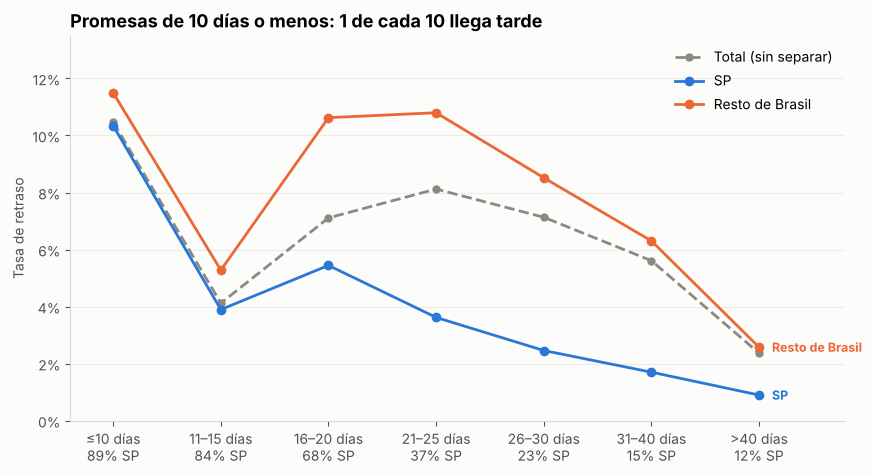

n                   tasa       
region      Resto de Brasil     SP Resto de Brasil     SP
tramo_plazo                                              
≤10                     435   3510           0.115  0.103
11–15                  1648   8446           0.053  0.039
16–20                  5346  11278           0.106  0.054
21–25                 16540   9833           0.108  0.036
26–30                 15086   4471           0.085  0.025
31–40                 13596   2411           0.063  0.017
>40                    3144    445           0.026  0.009

Plazo prometido promedio (días) según si el pedido se retrasó:


pedido_retrasado,puntual,retrasado,diferencia
region,,,
Resto de Brasil,27.8,25.8,2.0
SP,19.8,16.8,3.0


In [8]:
cortes = [0, 10, 15, 20, 25, 30, 40, 200]
nombres = ["≤10", "11–15", "16–20", "21–25", "26–30", "31–40", ">40"]
df["tramo_plazo"] = pd.cut(df["promised_days"], cortes, labels=nombres)

total = tasa_por(df, "tramo_plazo")
por_region = df.groupby(["tramo_plazo", "region"], observed=True)[TARGET_COL].agg(n="size", tasa="mean")
share_sp = df.groupby("tramo_plazo", observed=True)["region"].apply(lambda s: s.eq("SP").mean())

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(nombres))
ax.plot(x, total["tasa"], color=GRIS, lw=2, ls="--", marker="o", ms=5, label="Total (sin separar)")
for region, color in [("SP", AZUL), ("Resto de Brasil", NARANJA)]:
    serie = por_region.xs(region, level="region")["tasa"].reindex(nombres)
    ax.plot(x, serie, color=color, lw=2, marker="o", ms=6, label=region)
    ax.text(x[-1] + 0.12, serie.iloc[-1], region, color=color, va="center", fontsize=9, fontweight="bold")

ax.set_xticks(x, [f"{n} días\n{s:.0%} SP" for n, s in zip(nombres, share_sp)])
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0, 0.135)
ax.set_xlim(-0.4, len(x) - 0.2)
ax.set_ylabel("Tasa de retraso")
ax.legend(loc="upper right")
ax.set_title("Promesas de 10 días o menos: 1 de cada 10 llega tarde")
guardar(fig, "04_plazo_prometido")
plt.show()

display(por_region.unstack("region").round(3))

# La comparación de medias del notebook 01, ahora separada por región.
print("Plazo prometido promedio (días) según si el pedido se retrasó:")
display(df.pivot_table(index="region", columns=TARGET_COL, values="promised_days", aggfunc="mean")
          .rename(columns={0: "puntual", 1: "retrasado"})
          .assign(diferencia=lambda d: d["puntual"] - d["retrasado"]).round(1))

**Lectura:**
- **Las promesas de 10 días o menos son las que más fallan**, en las dos regiones (10,3 % en SP y 11,5 % en el resto). Lectura logística: el plazo es el **margen de seguridad**, y con 10 días o menos no alcanza para absorber un imprevisto.
- **Desde los 21–25 días, cuanto más plazo, menos retraso** en ambas regiones, hasta 0,9 % (SP) y 2,6 % (resto) con más de 40 días.
- La relación **no es lineal**. Fuera de SP hay un pozo en 11–15 días (5,3 %) y un máximo en 16–25 días (≈10,7 %). Un coeficiente lineal único para `promised_days` no captura esa forma.
- **Para un plazo igual, SP siempre se retrasa menos**, y la brecha crece con el plazo.
- **La geografía atenúa la relación.** Sin separar, los retrasados tienen 1,1 días menos de plazo. Dentro de SP la diferencia es de 3 días y dentro del resto, de 2. Mezclar SP (plazos cortos, poco retraso) con el resto (plazos largos, más retraso) achica la diferencia en el total. No la invierte, la diluye.

**Acción posible:** revisar el cálculo del plazo para promesas de 10 días o menos. El caso de junio de 2018 (gráfico 1) apunta en la misma dirección. Es una hipótesis: para confirmarla habría que probarla (por ejemplo, con un test A/B de plazos), no deducirla de datos observacionales.

**Para el modelo:** la forma no lineal y la diferencia entre regiones son otro argumento para probar un modelo de árboles junto a la regresión logística, o para usar tramos de plazo como variable.

## 5. Resumen para la demo

| # | Hallazgo | Por qué importa |
|---|---|---|
| 1 | El retraso no es estable: picos en nov-2017 (12,4 %) y feb–mar-2018 (hasta 19 %) | Justifica la validación temporal y sugiere alertas por temporada |
| 2 | Nordeste triplica la tasa; RJ tiene el 13 % de los pedidos y el 23 % de los retrasos | Dónde concentrar el esfuerzo operativo |
| 3 | El envío interestatal duplica el riesgo, pero **solo fuera de SP** | Hay una interacción que el modelo debe poder captar |
| 4 | Las promesas de ≤10 días fallan 1 de cada 10; desde los 25 días el riesgo cae | El plazo es el margen de seguridad, y su relación con el retraso no es lineal |

**Mensaje de cierre:** el retraso depende sobre todo de **adónde va el pedido, desde dónde sale y cuánto margen se prometió**. Esas tres cosas se conocen al aprobar el pago, por eso se puede predecir antes de que el pedido salga.

---
# Anexo (para preguntas, no para la demo)

## A. Cuando llega tarde, ¿cuánto tarde?

Usa la fecha real de entrega: **solo descriptivo, nunca entra al modelo.** Sirve para dimensionar el costo de un retraso.

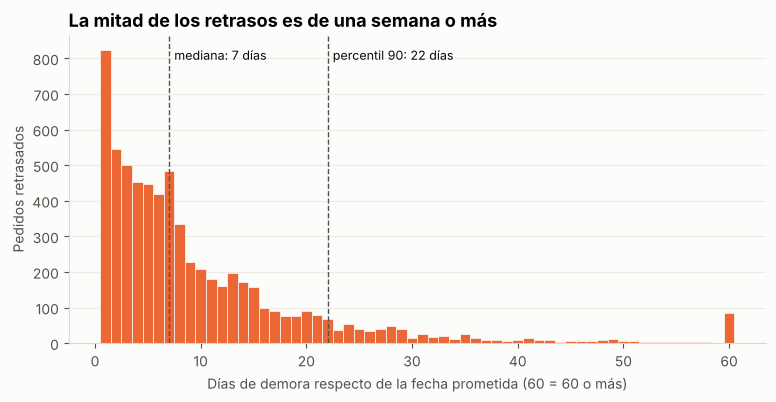

count    6531.0
mean       10.6
std        14.6
min         1.0
25%         3.0
50%         7.0
75%        13.0
max       188.0
dtype: float64


In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(dias_tarde.clip(upper=60), bins=np.arange(0.5, 61.5, 1), color=NARANJA, edgecolor="#fcfcfb", linewidth=0.5)
for q, nombre in [(0.5, "mediana"), (0.9, "percentil 90")]:
    v = dias_tarde.quantile(q)
    ax.axvline(v, color=TINTA_2, ls="--", lw=1)
    ax.text(v + 0.5, ax.get_ylim()[1] * 0.92, f"{nombre}: {v:.0f} días", fontsize=9, color=TINTA)
ax.set_xlabel("Días de demora respecto de la fecha prometida (60 = 60 o más)")
ax.set_ylabel("Pedidos retrasados")
ax.set_title("La mitad de los retrasos es de una semana o más")
guardar(fig, "A_dias_de_demora")
plt.show()
print(dias_tarde.describe().round(1))

## B. Variables que casi no separan

Mostrar lo que **no** funciona también es un resultado. Si el jurado pregunta "¿probaron el flete o la demora del pago?", esta es la respuesta.

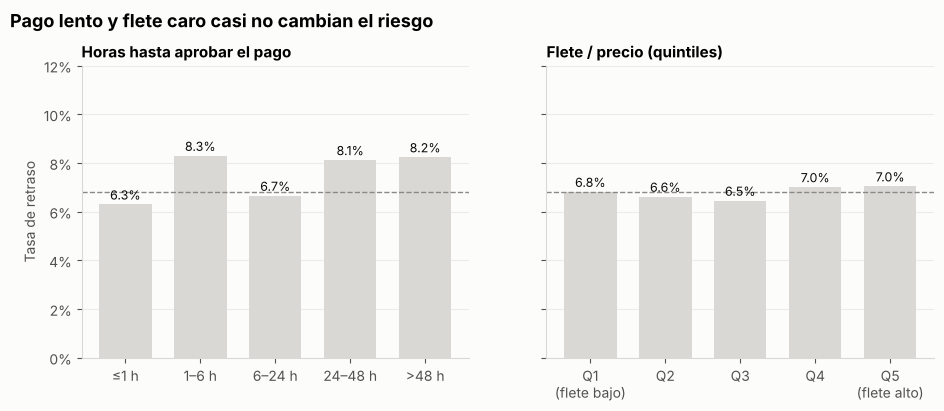

In [10]:
df["tramo_aprobacion"] = pd.cut(df["approval_hours"], [-0.01, 1, 6, 24, 48, df["approval_hours"].max()],
                                labels=["≤1 h", "1–6 h", "6–24 h", "24–48 h", ">48 h"])
df["quintil_flete"] = pd.qcut(df["freight_ratio"], 5, labels=["Q1\n(flete bajo)", "Q2", "Q3", "Q4", "Q5\n(flete alto)"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, col, titulo in [(axes[0], "tramo_aprobacion", "Horas hasta aprobar el pago"),
                        (axes[1], "quintil_flete", "Flete / precio (quintiles)")]:
    t = tasa_por(df, col)
    ax.bar(range(len(t)), t["tasa"], color=GRIS_CLARO, width=0.7)
    ax.set_xticks(range(len(t)), t.index)
    linea_global(ax, TASA_GLOBAL)
    for i, (tasa, n) in enumerate(zip(t["tasa"], t["n"])):
        ax.text(i, tasa + 0.002, f"{tasa:.1%}", ha="center", fontsize=9, color=TINTA)
    ax.set_title(titulo, fontsize=11)
axes[0].yaxis.set_major_formatter(pct)
axes[0].set_ylabel("Tasa de retraso")
axes[0].set_ylim(0, 0.12)
fig.suptitle("Pago lento y flete caro casi no cambian el riesgo", x=0.06, ha="left", fontweight="bold", fontsize=13)
fig.subplots_adjust(top=0.84)
guardar(fig, "B_variables_debiles")
plt.show()

**Lectura:** la proporción flete/precio es plana (6,5 % a 7,0 % en todos los quintiles). Las horas de aprobación van de 6,3 % a 8,3 %, una señal débil. Que no separen solas no significa que el modelo deba descartarlas: pueden aportar combinadas con otras. Eso lo decide la selección de variables del modelo, no este gráfico.

## C. Una rareza para investigar

Los pedidos con **dos o más vendedores** se retrasan mucho menos (1,0 %) que los de un solo vendedor (6,9 %). Es contraintuitivo: más vendedores deberían ser más puntos de falla.

Hipótesis descartadas con la tabla de abajo: no tienen un plazo más largo (mediana 25 contra 24 días) ni más clientes en SP (44 % contra 42 %). Queda una hipótesis abierta sobre **cómo se registra la entrega**: si un pedido con varios paquetes se marca como entregado cuando llega el primero, el target estaría midiendo mal esos casos. Son 1.272 pedidos (1,3 %): no cambia el modelo, pero conviene saberlo si el jurado pregunta.

In [11]:
display(
    df.assign(n_vendedores=np.where(df["n_sellers"] >= 2, "2 o más", "1"))
      .groupby("n_vendedores")
      .agg(n=(TARGET_COL, "size"), tasa=(TARGET_COL, "mean"), plazo_mediano=("promised_days", "median"),
           proporcion_sp=("region", lambda s: s.eq("SP").mean()))
      .round(3)
)

,n,tasa,plazo_mediano,proporcion_sp
n_vendedores,,,,
1,94917,0.069,24.0,0.420
2 o más,1272,0.010,25.0,0.444
